In [2]:
# Cell 1: shared setup (run first)
import json, glob, os
import pandas as pd
import matplotlib.pyplot as plt

D = "../pipeline/data"                 # notebook lives in notebooks/
P = f"{D}/processed"
TOWNS = {"guimba": "Guimba", "munoz": "Muñoz", "bongabon": "Bongabon"}
COLORS = {"guimba": "#1f77b4", "munoz": "#ff7f0e", "bongabon": "#2ca02c"}

# El Niño dry seasons from enso.py (NOAA episode rule), as (Nov of y-1, Apr of y)
enso = pd.read_csv(f"{P}/enso_dryseason.csv")
ELNINO_DS = [(f"{y - 1}-11", f"{y}-04") for y in enso.loc[enso.tag_episode == "el_nino", "harvest_year"]
             if 2002 <= y <= 2025]
print("El Niño dry seasons:", ", ".join(enso.loc[enso.tag_episode == "el_nino", "dry_season"]
                                        .loc[lambda s: s.str[:4].astype(int).between(2001, 2024)]))

def shade_elnino(ax):
    for a, b in ELNINO_DS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.offsets.MonthEnd(), color="grey", alpha=0.15, lw=0)

El Niño dry seasons: 2002-03, 2004-05, 2006-07, 2009-10, 2014-15, 2015-16, 2018-19, 2019-20, 2023-24


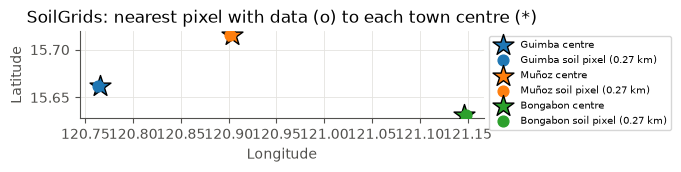

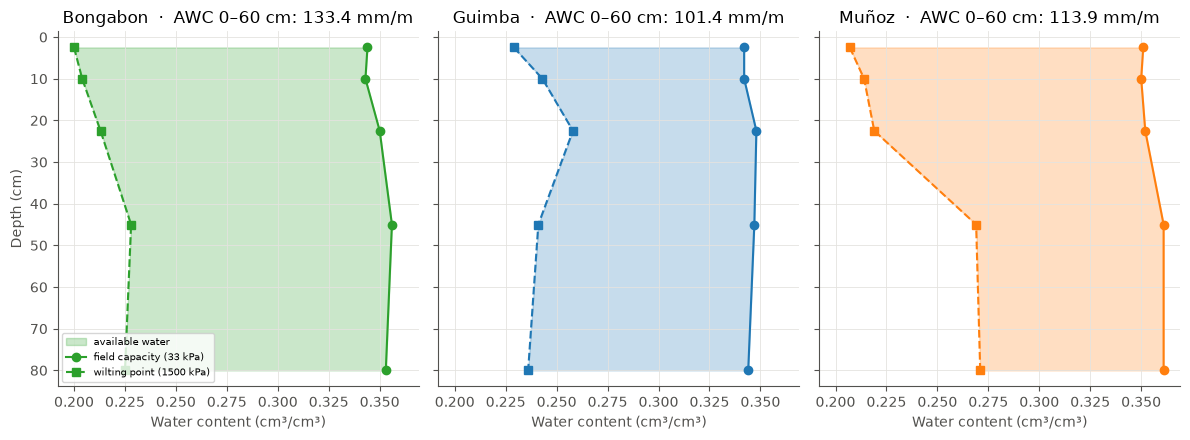

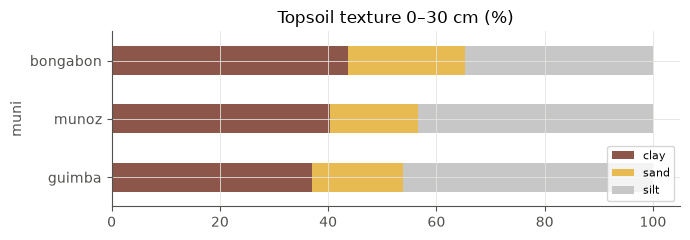

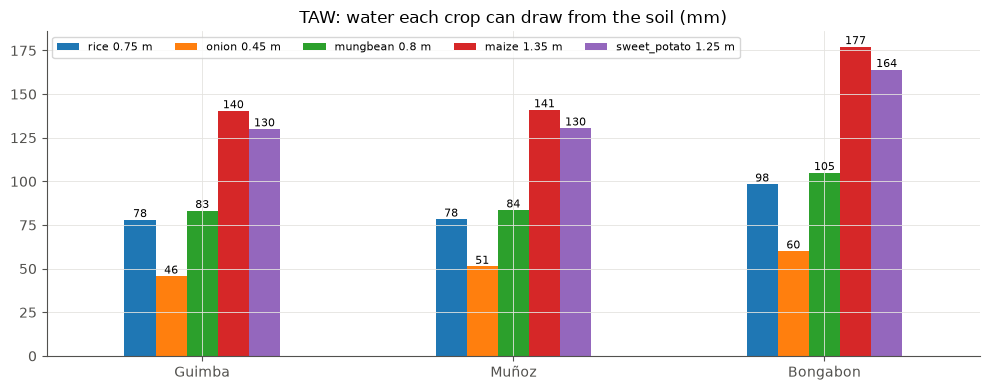

,lat,lon,theta_fc_0_30,theta_wp_0_30,awc_mm_per_m_0_30,theta_fc_0_60,theta_wp_0_60,awc_mm_per_m_0_60,theta_fc_0_100,theta_wp_0_100,awc_mm_per_m_0_100,clay_pct_0_30,sand_pct_0_30,town_lat,town_lon,km_from_town,n_pixels
muni,,,,,,,,,,,,,,,,,
guimba,15.662,120.763,0.345,0.248,96.8,0.346,0.245,101.4,0.345,0.241,104.0,37.0,16.8,15.662,120.766,0.27,1
munoz,15.715,120.901,0.351,0.215,135.8,0.356,0.242,113.9,0.358,0.254,104.4,40.4,16.2,15.715,120.904,0.27,1
bongabon,15.632,121.148,0.347,0.208,138.8,0.351,0.218,133.4,0.352,0.221,131.2,43.6,21.6,15.632,121.146,0.27,1


In [3]:
# Cell 2: soil (SoilGrids)
soil = pd.read_csv(f"{P}/soil.csv").set_index("muni")
crops = pd.read_csv(f"{D}/raw/crops.csv")

def load(path):
    doc = json.load(open(path))
    lon, lat = doc["geometry"]["coordinates"][:2]
    rows = [{"prop": L["name"], "top": d["range"]["top_depth"], "bottom": d["range"]["bottom_depth"],
             "v": d["values"].get("mean")} for L in doc["properties"]["layers"] for d in L["depths"]]
    df = pd.DataFrame(rows).pivot(index=["top", "bottom"], columns="prop", values="v").reset_index()
    df["mid"] = (df.top + df.bottom) / 2
    return lat, lon, df

files = {os.path.basename(f)[5:].split(".")[0].lower(): f for f in glob.glob(f"{D}/raw/SOIL_*.json")}

# 1. Where the soil comes from: town centre (*) -> nearest valid soil pixel (o)
fig, ax = plt.subplots(figsize=(7, 6))
for m, r in soil.iterrows():
    c = COLORS[m]
    ax.scatter(r.town_lon, r.town_lat, marker="*", s=250, color=c, edgecolor="k", zorder=3, label=f"{TOWNS[m]} centre")
    ax.scatter(r.lon, r.lat, marker="o", s=60, color=c, zorder=3, label=f"{TOWNS[m]} soil pixel ({r.km_from_town} km)")
    ax.plot([r.town_lon, r.lon], [r.town_lat, r.lat], color=c, lw=1)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")
ax.set_title("SoilGrids: nearest pixel with data (o) to each town centre (*)")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

# 2. Water retention by depth: the shaded gap is water a crop can use
fig, axes = plt.subplots(1, len(files), figsize=(4 * len(files), 4.5), sharey=True, sharex=True)
for ax, (m, f) in zip(axes, sorted(files.items())):
    _, _, L = load(f)
    ax.fill_betweenx(L.mid, L.wv1500 / 1000, L.wv0033 / 1000, color=COLORS[m], alpha=0.25, label="available water")
    ax.plot(L.wv0033 / 1000, L.mid, "o-", color=COLORS[m], label="field capacity (33 kPa)")
    ax.plot(L.wv1500 / 1000, L.mid, "s--", color=COLORS[m], label="wilting point (1500 kPa)")
    ax.set_title(f"{TOWNS[m]}  ·  AWC 0–60 cm: {soil.loc[m, 'awc_mm_per_m_0_60']} mm/m")
    ax.set_xlabel("Water content (cm³/cm³)")
axes[0].invert_yaxis(); axes[0].set_ylabel("Depth (cm)"); axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

# 3. Texture: why the towns differ
soil[["clay_pct_0_30", "sand_pct_0_30"]].assign(silt=lambda d: 100 - d.clay_pct_0_30 - d.sand_pct_0_30) \
    .rename(columns={"clay_pct_0_30": "clay", "sand_pct_0_30": "sand"}) \
    .plot.barh(stacked=True, figsize=(7, 2.5), color=["#8c564b", "#e7ba52", "#c7c7c7"],
               title="Topsoil texture 0–30 cm (%)").legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

# 4. Bucket size per crop: TAW = AWC (soil layer reaching the roots) x root depth from crops.csv
def awc_col(zr):
    return "awc_mm_per_m_0_30" if zr <= 0.3 else "awc_mm_per_m_0_60" if zr <= 0.6 else "awc_mm_per_m_0_100"
zr = crops[crops.param == "root_depth_m"].set_index("crop").value
taw = pd.DataFrame({f"{c} {z:g} m": soil[awc_col(z)].fillna(soil.awc_mm_per_m_0_60) * z for c, z in zr.items()})
taw.index = [TOWNS[m] for m in taw.index]
ax = taw.plot.bar(figsize=(10, 4), rot=0, title="TAW: water each crop can draw from the soil (mm)")
for c in ax.containers: ax.bar_label(c, fmt="%.0f", fontsize=8)
ax.legend(fontsize=8, ncol=5, loc="upper left"); plt.tight_layout(); plt.show()

soil.round(3)

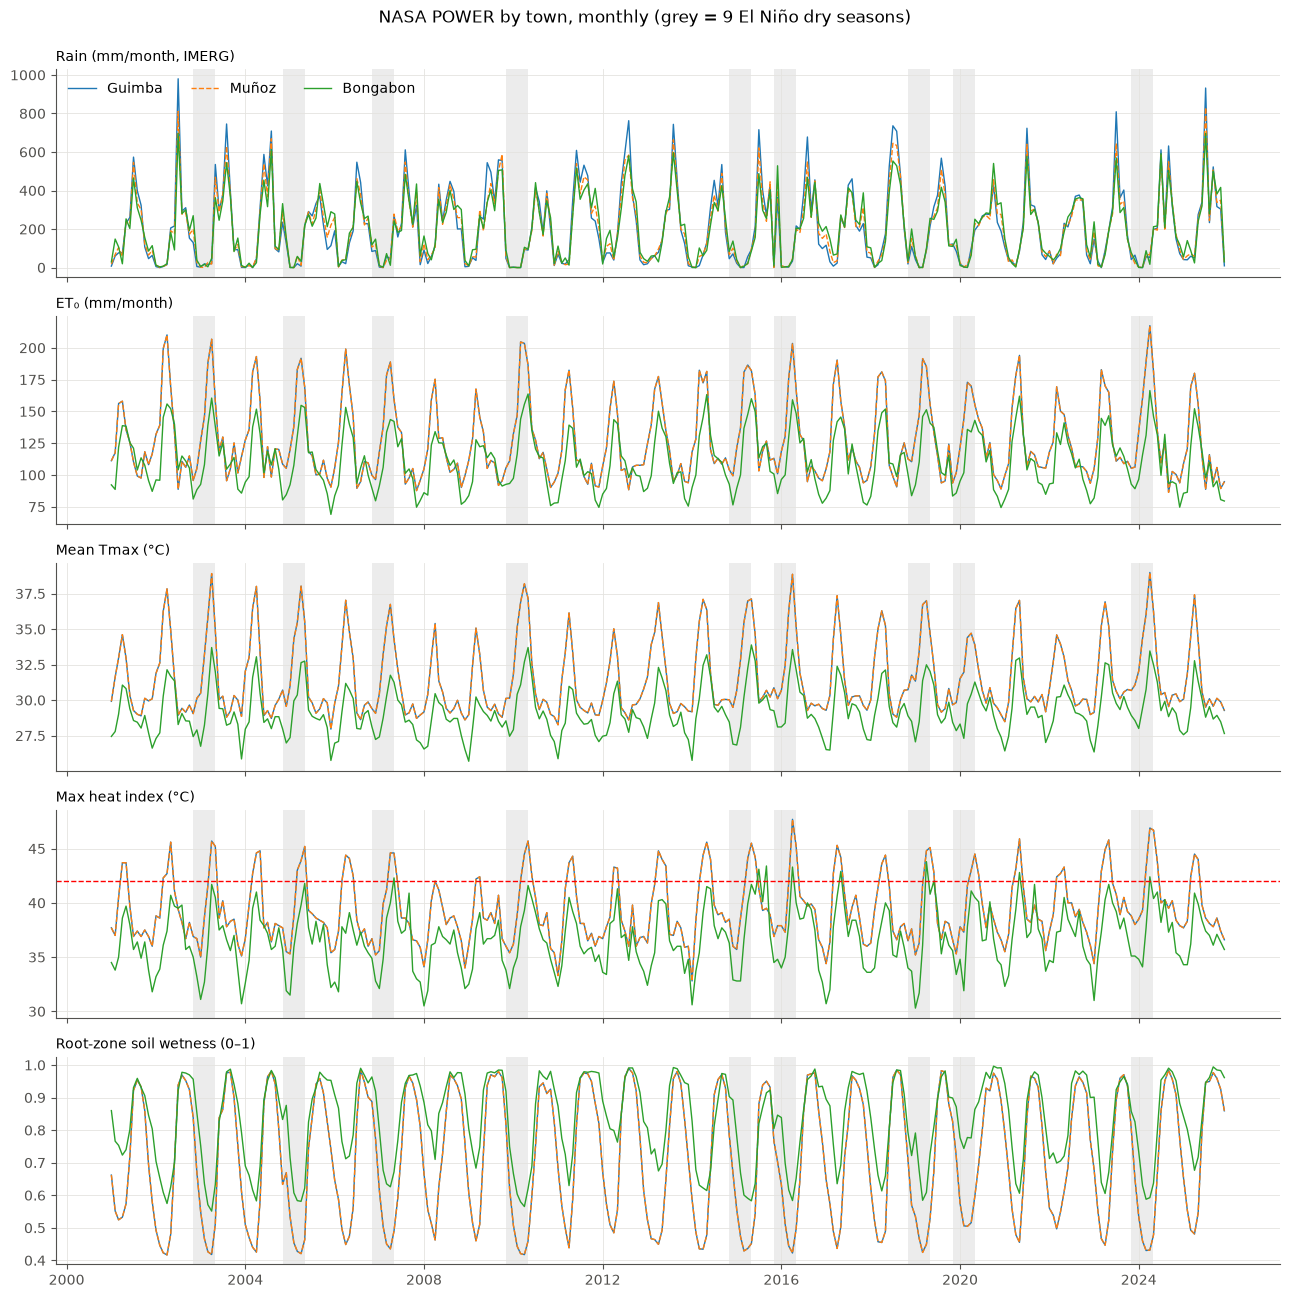

In [4]:
# Cell 3: NASA POWER by town
daily = {k: pd.read_csv(f"{P}/power_{k}.csv", index_col="date", parse_dates=True) for k in TOWNS}
panels = [
    ("PRECTOTCORR", "sum",  "Rain (mm/month, IMERG)"),
    ("ET0",         "sum",  "ET₀ (mm/month)"),
    ("T2M_MAX",     "mean", "Mean Tmax (°C)"),
    ("HI",          "max",  "Max heat index (°C)"),
    ("GWETROOT",    "mean", "Root-zone soil wetness (0–1)"),
]
fig, axes = plt.subplots(len(panels), 1, figsize=(13, 13), sharex=True)
for ax, (col, how, title) in zip(axes, panels):
    shade_elnino(ax)
    for k, d in daily.items():
        s = getattr(d[col].resample("MS"), how)()
        ax.plot(s.index, s, color=COLORS[k], lw=1, label=TOWNS[k], ls="--" if k == "munoz" else "-")
    ax.set_title(title, loc="left", fontsize=10)
    if col == "HI":
        ax.axhline(42, color="red", ls="--", lw=1)     # PAGASA danger
axes[0].legend(loc="upper left", ncol=3, frameon=False)
fig.suptitle(f"NASA POWER by town, monthly (grey = {len(ELNINO_DS)} El Niño dry seasons)", y=0.995)
plt.tight_layout(); plt.show()

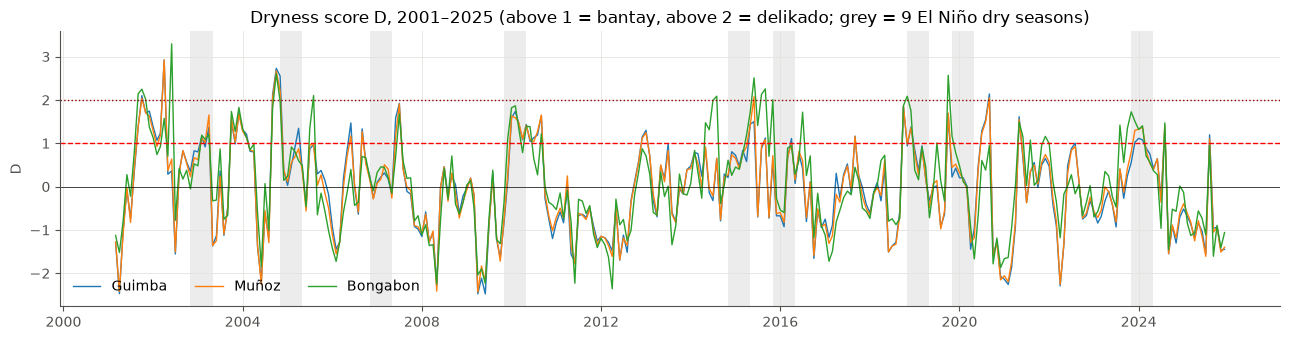

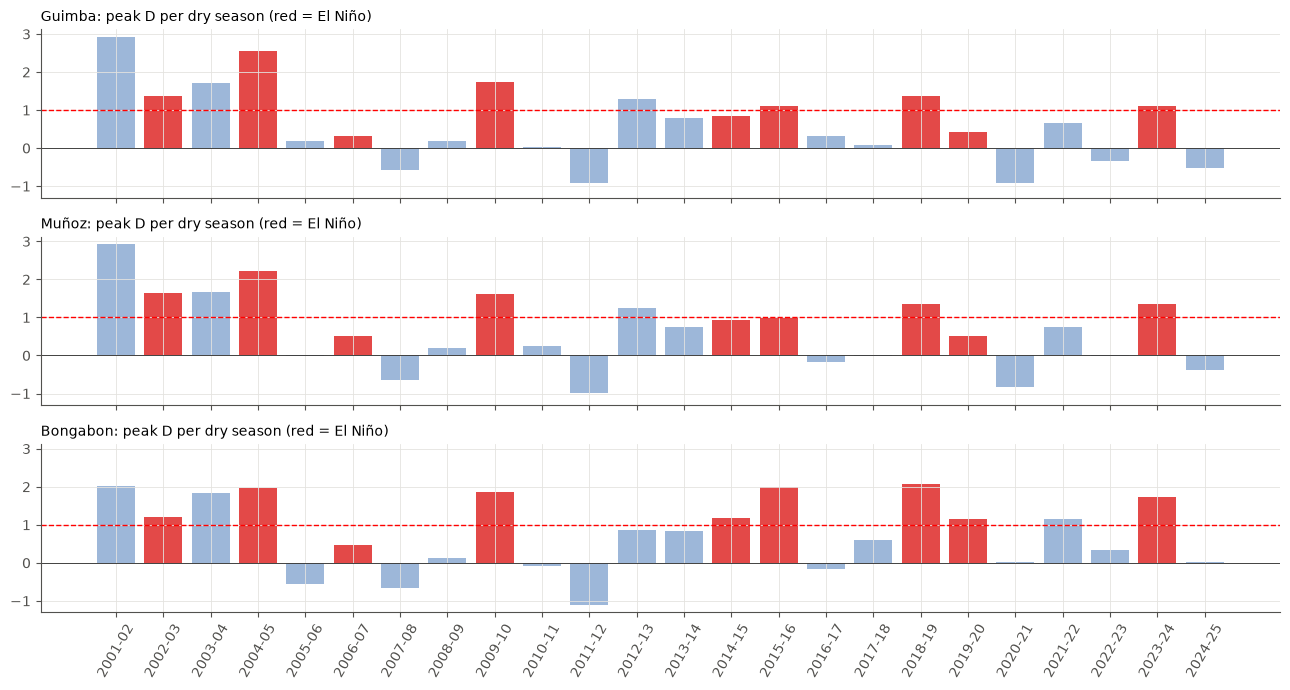

In [7]:
# Cell 4: dryness score D
monthly = {k: pd.read_csv(f"{P}/monthly_{k}.csv", index_col="month", parse_dates=True) for k in TOWNS}
fig, ax = plt.subplots(figsize=(13, 3.5))
shade_elnino(ax)
for k, m in monthly.items():
    ax.plot(m.index, m["D"], color=COLORS[k], lw=1, label=TOWNS[k])
ax.axhline(1, color="red", ls="--", lw=1); ax.axhline(2, color="darkred", ls=":", lw=1); ax.axhline(0, color="black", lw=0.5)
ax.set_title(f"Dryness score D, 2001–2025 (above 1 = bantay, above 2 = delikado; grey = {len(ELNINO_DS)} El Niño dry seasons)")
ax.set_ylabel("D"); ax.legend(loc="lower left", ncol=3, frameon=False)
plt.tight_layout(); plt.show()

# Cell 4b: peak dryness of each dry season (Nov–Apr only), El Niño seasons in red
en_seasons = set(enso.loc[enso.tag_episode == "el_nino", "dry_season"])
fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True, sharey=True)
for ax, (k, m) in zip(axes, monthly.items()):
    ds = m[m.index.month.isin([11, 12, 1, 2, 3, 4])].copy()
    start = ds.index.year - (ds.index.month <= 4)            # Jan–Apr belong to the season that began the year before
    ds["season"] = [f"{y}-{str(y + 1)[-2:]}" for y in start]
    peak = ds.groupby("season").D.max()
    peak = peak[[s[:4] >= "2001" and s[:4] <= "2024" for s in peak.index]]
    ax.bar(peak.index, peak.values, color=["#e34948" if s in en_seasons else "#9db7d9" for s in peak.index])
    ax.axhline(1, color="red", ls="--", lw=1); ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"{TOWNS[k]}: peak D per dry season (red = El Niño)", loc="left", fontsize=10)
axes[-1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()